# 03 — Aprendizaje supervisado: reconocimiento de actividades humanas


Entrenar y comparar dos clasificadores multiclase para reconocer seis actividades humanas a partir de 561 variables de sensores de teléfonos inteligentes. Se parte de los archivos preparados en `02_preprocesamiento.ipynb` y se mantiene separada la prueba oficial del dataset HAR (personas no vistas durante el entrenamiento).

**Modelos:** regresión logística y Random Forest. **Métricas:** Accuracy, Macro F1-score, informe por clase y matriz de confusión.

> **Instrucción:** ejecutar primero `02_preprocesamiento.ipynb` para crear `data/procesado/train.pkl` y `test.pkl`. Este notebook no modifica ni desarrolla `04_no_supervisado`.

## 1. Bibliotecas y carga de datos
Los archivos `.pkl` tienen 561 variables predictoras y cuatro columnas auxiliares: `actividad_id`, `actividad`, `grupo` y `persona`. La columna `grupo` representa estática/dinámica, por lo que **no debe entrar al clasificador**, al igual que las otras columnas auxiliares.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)

# Compatible con ejecución desde la carpeta notebooks/ o desde la raíz evaluacion 4/.
carpetas = [Path('../data/procesado'), Path('data/procesado'),
            Path('evaluacion 4/data/procesado')]
data_dir = next((d for d in carpetas if (d / 'train.pkl').exists() and
                 (d / 'test.pkl').exists()), None)
if data_dir is None:
    raise FileNotFoundError(
        'No se encontraron train.pkl y test.pkl. Ejecuta primero 02_preprocesamiento.ipynb '
        'con el dataset HAR descargado en evaluacion 4/data/. '
        'Si trabajas en Colab, sube estos archivos junto al notebook y ajusta data_dir.')

train = pd.read_pickle(data_dir / 'train.pkl')
test = pd.read_pickle(data_dir / 'test.pkl')
auxiliares = ['actividad_id', 'actividad', 'grupo', 'persona']
assert all(c in train.columns and c in test.columns for c in auxiliares)
X_train = train.drop(columns=auxiliares)
X_test = test.drop(columns=auxiliares)
y_train = train['actividad_id'].astype(int)
y_test = test['actividad_id'].astype(int)
s_train = train['persona']
assert list(X_train.columns) == list(X_test.columns), 'Las columnas de entrenamiento y prueba deben coincidir'
assert not X_train.isna().any().any() and not X_test.isna().any().any()
assert set(s_train).isdisjoint(set(test['persona'])), 'La prueba debe contener participantes diferentes'

etiquetas = sorted(set(y_train) | set(y_test))
nombres = (pd.concat([train[['actividad_id','actividad']],test[['actividad_id','actividad']]])
           .drop_duplicates('actividad_id').set_index('actividad_id')['actividad'].to_dict())
nombres_ordenados = [nombres[i] for i in etiquetas]
print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('Número de actividades:', len(etiquetas))
print('Participantes entrenamiento:', s_train.nunique(), '| prueba:', test['persona'].nunique())
print('Clases:', nombres)

Entrenamiento: (7352, 561) | Prueba: (2947, 561)
Número de actividades: 6
Participantes entrenamiento: 21 | prueba: 9
Clases: {5: 'STANDING', 4: 'SITTING', 6: 'LAYING', 1: 'WALKING', 3: 'WALKING_DOWNSTAIRS', 2: 'WALKING_UPSTAIRS'}


## 2. Modelos y justificación

**Regresión logística multinomial:** sirve como línea base interpretable y eficiente para clasificación de varias clases. Requiere escalar las variables porque utiliza regularización; el `StandardScaler` se ajusta exclusivamente sobre los datos de cada partición de entrenamiento mediante `Pipeline`. Sus fronteras de decisión son lineales, lo que puede limitarla ante relaciones complejas.

**Random Forest:** combina árboles de decisión y captura relaciones no lineales e interacciones entre variables. No requiere escalamiento, pero puede ser más costoso computacionalmente y menos interpretable. Su importancia de variables se debe tratar con cautela ante características altamente correlacionadas.

Se utiliza `GroupKFold` por `persona` para que los sujetos de entrenamiento y validación sean distintos. La prueba oficial se reserva para evaluación final.

In [3]:
modelos = {
    'Regresión logística': Pipeline([
        ('escalado', StandardScaler()),
        ('modelo', LogisticRegression(C=0.1, max_iter=3000, random_state=SEED))
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2,
        random_state=SEED, n_jobs=-1
    )
}
validacion = GroupKFold(n_splits=5)
filas_cv = []
for nombre, modelo in modelos.items():
    puntajes = cross_validate(
        modelo, X_train, y_train, groups=s_train, cv=validacion,
        scoring={'accuracy':'accuracy','macro_f1':'f1_macro'}, n_jobs=1
    )
    filas_cv.append({
        'Modelo': nombre,
        'Accuracy CV (media)': puntajes['test_accuracy'].mean(),
        'Accuracy CV (desv.)': puntajes['test_accuracy'].std(),
        'Macro F1 CV (media)': puntajes['test_macro_f1'].mean(),
        'Macro F1 CV (desv.)': puntajes['test_macro_f1'].std(),
    })
comparacion_cv = pd.DataFrame(filas_cv).sort_values('Macro F1 CV (media)', ascending=False)
display(comparacion_cv.round(4))

,Modelo,Accuracy CV (media),Accuracy CV (desv.),Macro F1 CV (media),Macro F1 CV (desv.)
0,Regresión logística,0.9348,0.0397,0.9339,0.0427
1,Random Forest,0.9192,0.0423,0.9181,0.0432


## 3. Entrenamiento definitivo y evaluación con participantes no vistos

Se ajusta cada algoritmo con **todo el conjunto de entrenamiento** y se evalúa una sola vez con `test.pkl`. No se usan las observaciones de prueba para ajustar parámetros ni transformaciones.

In [4]:
modelos_ajustados = {}
predicciones = {}
filas_test = []
for nombre, modelo in modelos.items():
    ajustado = clone(modelo).fit(X_train, y_train)
    pred = ajustado.predict(X_test)
    modelos_ajustados[nombre] = ajustado
    predicciones[nombre] = pred
    filas_test.append({
        'Modelo': nombre,
        'Accuracy test': accuracy_score(y_test, pred),
        'Macro F1 test': f1_score(y_test, pred, average='macro'),
    })
comparacion_test = pd.DataFrame(filas_test).sort_values('Macro F1 test', ascending=False)
display(comparacion_test.round(4))
for nombre, pred in predicciones.items():
    print(f'\n=== {nombre} — reporte por actividad ===')
    print(classification_report(y_test, pred, labels=etiquetas,
                                target_names=nombres_ordenados, zero_division=0))

,Modelo,Accuracy test,Macro F1 test
0,Regresión logística,0.9498,0.950
1,Random Forest,0.9240,0.922



=== Regresión logística — reporte por actividad ===
                    precision    recall  f1-score   support

           WALKING       0.94      0.99      0.97       496
  WALKING_UPSTAIRS       0.95      0.95      0.95       471
WALKING_DOWNSTAIRS       0.99      0.94      0.96       420
           SITTING       0.96      0.88      0.91       491
          STANDING       0.88      0.96      0.92       532
            LAYING       1.00      0.97      0.99       537

          accuracy                           0.95      2947
         macro avg       0.95      0.95      0.95      2947
      weighted avg       0.95      0.95      0.95      2947


=== Random Forest — reporte por actividad ===
                    precision    recall  f1-score   support

           WALKING       0.89      0.97      0.93       496
  WALKING_UPSTAIRS       0.89      0.90      0.90       471
WALKING_DOWNSTAIRS       0.97      0.84      0.90       420
           SITTING       0.92      0.88      0.90       

## 4. Visualizaciones: comparación y matrices de confusión

Las matrices permiten estudiar en qué actividades aparecen errores, especialmente entre movimientos parecidos como caminar y subir o bajar escaleras. Las filas representan la actividad verdadera y las columnas la predicha.

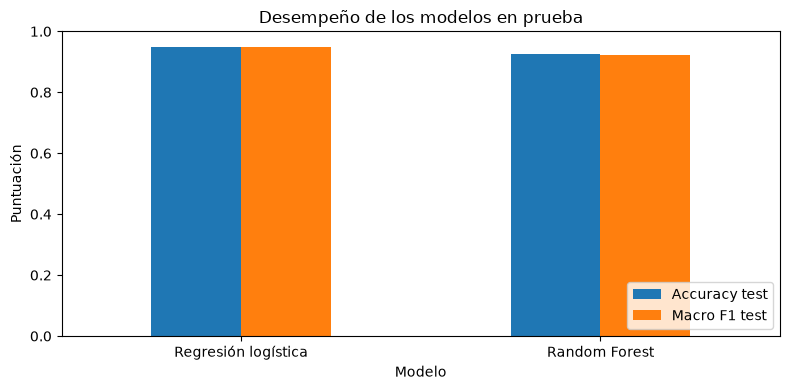

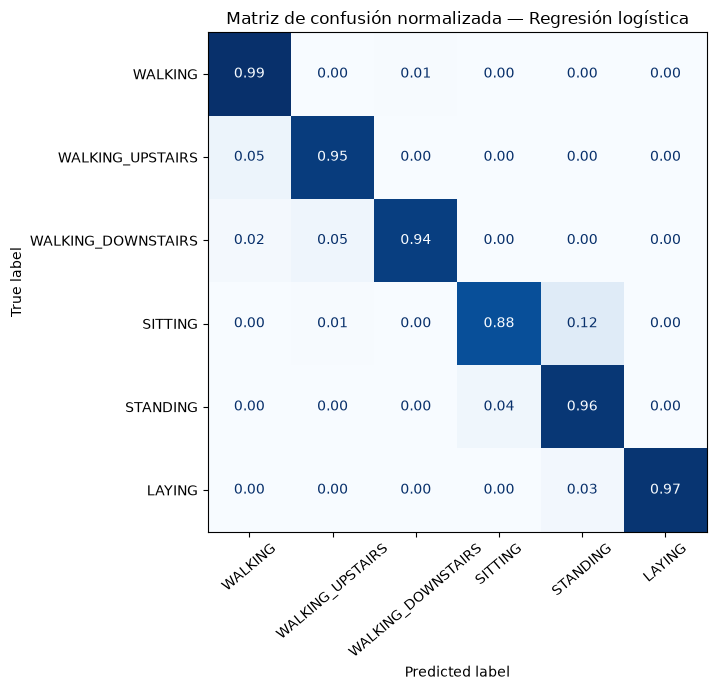

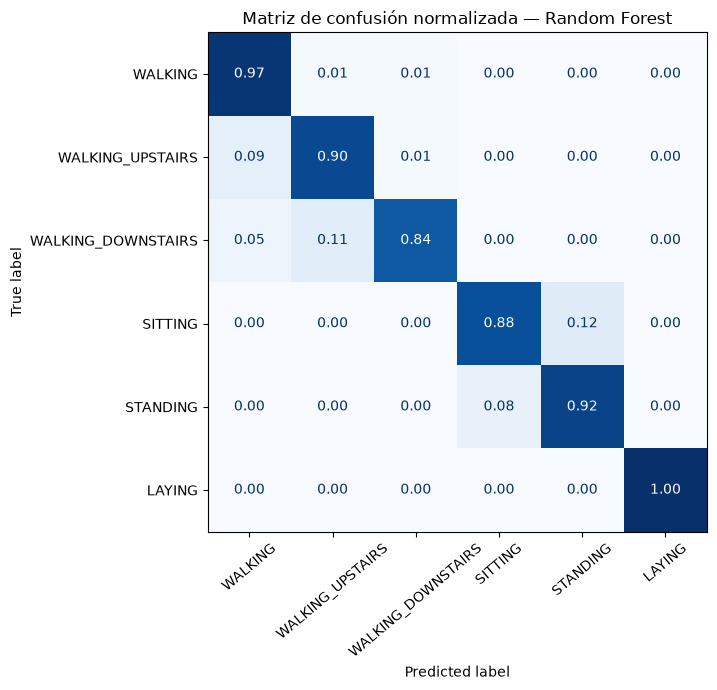

In [5]:
ax = comparacion_test.set_index('Modelo')[['Accuracy test','Macro F1 test']].plot(
    kind='bar', figsize=(8,4), rot=0, ylim=(0,1), title='Desempeño de los modelos en prueba')
ax.set_ylabel('Puntuación')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

for nombre, pred in predicciones.items():
    fig, ax = plt.subplots(figsize=(9,7))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=etiquetas, display_labels=nombres_ordenados,
        normalize='true', cmap='Blues', values_format='.2f', ax=ax,
        xticks_rotation=40, colorbar=False
    )
    ax.set_title(f'Matriz de confusión normalizada — {nombre}')
    plt.tight_layout()
    plt.show()

## 5. Actividades con mayor confusión

A continuación se presentan los errores más frecuentes de cada modelo, excluyendo los aciertos de la diagonal. Su interpretación debe relacionarse con similitudes físicas entre las actividades.

In [6]:
for nombre, pred in predicciones.items():
    matriz = confusion_matrix(y_test, pred, labels=etiquetas)
    np.fill_diagonal(matriz, 0)
    confusiones = []
    for i, j in zip(*np.where(matriz > 0)):
        confusiones.append((nombres_ordenados[i], nombres_ordenados[j], int(matriz[i,j])))
    confusiones.sort(key=lambda r: r[2], reverse=True)
    print(f'\n{nombre}: principales confusiones (real → predicha)')
    display(pd.DataFrame(confusiones[:8], columns=['Actividad real','Predicha como','Casos']))


Regresión logística: principales confusiones (real → predicha)


,Actividad real,Predicha como,Casos
0,SITTING,STANDING,58
1,WALKING_UPSTAIRS,WALKING,24
2,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS,19
3,STANDING,SITTING,19
4,LAYING,STANDING,14
5,WALKING_DOWNSTAIRS,WALKING,7
6,WALKING,WALKING_DOWNSTAIRS,3
7,SITTING,WALKING_UPSTAIRS,3



Random Forest: principales confusiones (real → predicha)


,Actividad real,Predicha como,Casos
0,SITTING,STANDING,58
1,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS,45
2,WALKING_UPSTAIRS,WALKING,41
3,STANDING,SITTING,40
4,WALKING_DOWNSTAIRS,WALKING,21
5,WALKING,WALKING_UPSTAIRS,7
6,WALKING,WALKING_DOWNSTAIRS,6
7,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,6


## 6. ¿Estático vs. dinámico es más fácil?

La etiqueta binaria estática/dinámica se **deriva de las predicciones de seis clases ya obtenidas**. Por tanto, se trata de una comparación descriptiva para entender los errores, **no de un tercer clasificador entrenado**. Esta comparación puede dar una puntuación mayor porque los errores dentro de un mismo grupo dejan de contar como errores.

In [7]:
dinamicas = {1,2,3}  # WALKING, WALKING_UPSTAIRS y WALKING_DOWNSTAIRS
real_bin = np.array(['dinámica' if int(v) in dinamicas else 'estática' for v in y_test])
comparacion_grupos = []
for nombre, pred in predicciones.items():
    pred_bin = np.array(['dinámica' if int(v) in dinamicas else 'estática' for v in pred])
    comparacion_grupos.append({
        'Modelo': nombre,
        'Accuracy 6 actividades': accuracy_score(y_test,pred),
        'Accuracy estática/dinámica (derivada)':accuracy_score(real_bin,pred_bin)
    })
display(pd.DataFrame(comparacion_grupos).round(4))

,Modelo,Accuracy 6 actividades,Accuracy estática/dinámica (derivada)
0,Regresión logística,0.9498,0.999
1,Random Forest,0.9240,1.000


## 7. Exportación de métricas y predicciones

os resultados del componente supervisado se guardan en la carpeta `resultados_supervisado/`, ubicada directamente en `evaluacion 4/`, fuera de la carpeta `data/`.

Se generan tres archivos CSV:

- `metricas_validacion.csv`: resultados de la validación cruzada.
- `metricas_prueba.csv`: métricas de evaluación de los modelos en el conjunto de prueba.
- `predicciones_test.csv`: comparación entre las actividades reales y las predicciones de ambos modelos.


In [9]:

# Crear carpeta de resultados fuera de data/

carpeta_salida = data_dir.parent.parent / 'resultados_supervisado'
carpeta_salida.mkdir(parents=True, exist_ok=True)

# Exportar métricas de validación y prueba
comparacion_cv.to_csv(
    carpeta_salida / 'metricas_validacion.csv',
    index=False
)

comparacion_test.to_csv(
    carpeta_salida / 'metricas_prueba.csv',
    index=False
)

# Construir archivo con las predicciones de ambos modelos
salida = pd.DataFrame({
    'actividad_real_id': y_test.to_numpy(),
    'actividad_real': [nombres[int(y)] for y in y_test]
})

for nombre, pred in predicciones.items():
    sufijo = 'logistica' if nombre == 'Regresión logística' else 'random_forest'

    salida[f'pred_{sufijo}_id'] = pred
    salida[f'pred_{sufijo}'] = [
        nombres[int(y)] for y in pred
    ]

# Guardar predicciones
salida.to_csv(
    carpeta_salida / 'predicciones_test.csv',
    index=False
)

print('Archivos generados correctamente:')
print('Ubicación:', carpeta_salida.resolve())
print(salida.shape)
print('\nArchivos:', list(carpeta_salida.iterdir()))


Archivos generados correctamente:
Ubicación: D:\2. Estudios\4. Ingenieria Sistemas\Semestre 10\Análisis de datos\Entregable 4\analisis-datos-grupo7\evaluacion 4\resultados_supervisado
(2947, 6)

Archivos: [WindowsPath('../resultados_supervisado/metricas_prueba.csv'), WindowsPath('../resultados_supervisado/metricas_validacion.csv'), WindowsPath('../resultados_supervisado/predicciones_test.csv')]


## 8. Interpretación y conclusiones

### 8.1. Desempeño comparado

Los resultados obtenidos muestran que la Regresión Logística presentó el mejor desempeño en la clasificación de las seis actividades humanas, alcanzando un Accuracy de 0.9498 (94.98 %), mientras que Random Forest obtuvo 0.9240 (92.40 %).

La diferencia evidencia que, para este conjunto de datos, la Regresión Logística logró una mejor capacidad de clasificación general. Además, su Macro F1-score también fue superior, según la comparación gráfica realizada, lo que indica un mejor equilibrio en el reconocimiento de las diferentes actividades.

Aunque Random Forest es un algoritmo capaz de identificar relaciones complejas entre variables, en este experimento no superó el desempeño del modelo lineal. Esto demuestra que una mayor complejidad algorítmica no garantiza necesariamente mejores resultados.

### 8.2. Errores entre actividades

Las matrices de confusión permiten identificar las principales dificultades de clasificación de ambos modelos.

En los dos algoritmos se presentó una confusión importante entre las actividades SIT­TING (sentado) y STANDING (de pie). En ambos casos, 58 registros correspondientes a personas sentadas fueron clasificados como personas de pie. La matriz normalizada muestra que esta confusión representa aproximadamente el 12 % de los registros de la clase SIT­TING.

Esta dificultad puede explicarse porque ambas actividades presentan características de movimiento relativamente similares: en las dos existe poca variación corporal y ausencia de desplazamiento significativo.

También se identificaron confusiones entre las actividades dinámicas. En particular, Random Forest presentó dificultades para diferenciar WALKING_DOWNSTAIRS (bajar escaleras) de WALKING_UPSTAIRS (subir escaleras), con un 11 % de confusión en esa dirección. Esto puede relacionarse con la similitud de los movimientos registrados por los sensores durante ambas actividades.

En general, los errores se concentran en actividades que comparten características físicas y patrones de movimiento, lo que representa uno de los principales desafíos del reconocimiento automático de actividades humanas.

### 8.3. Generalización

Un aspecto importante del experimento es que los datos de entrenamiento y prueba corresponden a personas diferentes. Esta separación permite evaluar la capacidad de los modelos para reconocer actividades en participantes que no estuvieron presentes durante el entrenamiento.

Por tanto, los resultados obtenidos ofrecen una evaluación más exigente que una partición aleatoria de registros, ya que reducen el riesgo de que el modelo simplemente reconozca patrones particulares de las personas utilizadas para entrenarlo.

Sin embargo, estos resultados no garantizan el mismo desempeño en cualquier población o dispositivo. Diferencias en la ubicación del teléfono, las características físicas de los usuarios, la forma de caminar y los sensores utilizados podrían modificar las señales y afectar las predicciones.

### 8.4. Distinguir entre actividades estáticas y dinámicas

Los resultados permiten responder afirmativamente a la pregunta de trabajo: distinguir entre actividades estáticas y dinámicas resulta más sencillo que reconocer individualmente las seis actividades.

Al agrupar las predicciones en estas dos categorías, la Regresión Logística alcanzó un Accuracy de 0.999 (99.9 %), mientras que Random Forest obtuvo 1.000 (100 %).

En cambio, cuando se requiere diferenciar las seis actividades, el desempeño disminuye, especialmente en aquellas que presentan patrones de movimiento similares, como estar sentado y de pie, o subir y bajar escaleras.

Esto evidencia que agrupar las actividades según características generales del movimiento simplifica considerablemente el problema de clasificación.

### 8.5. Elección para una aplicación práctica

Para una primera aplicación de reconocimiento de actividades humanas, se recomienda la Regresión Logística.

La elección se fundamenta en que obtuvo el mayor Accuracy en la clasificación de las seis actividades (94.98 %), presentó un Macro F1-score superior al de Random Forest y ofrece una estructura matemática más sencilla de interpretar.

Además, su menor complejidad puede favorecer tiempos de entrenamiento y predicción reducidos, aunque estos tiempos deben medirse para realizar una comparación computacional definitiva.

Random Forest también representa una alternativa válida, especialmente por su resultado en la distinción entre actividades estáticas y dinámicas. Sin embargo, para el objetivo principal de reconocer las seis actividades, la Regresión Logística presentó mejores resultados.

### 8.6. Conclusiones generales

El desarrollo del componente supervisado permitió comprobar que las señales obtenidas mediante los sensores de un teléfono inteligente contienen información suficiente para reconocer diferentes actividades humanas.

La comparación entre Regresión Logística y Random Forest mostró que ambos modelos alcanzaron resultados satisfactorios, aunque la Regresión Logística presentó un mejor desempeño en la clasificación de las seis categorías.

Las matrices de confusión permitieron identificar que las mayores dificultades se encuentran en actividades con características físicas similares, especialmente entre estar sentado y de pie, así como entre subir y bajar escaleras.

También se comprobó que la clasificación binaria entre actividades estáticas y dinámicas presenta resultados superiores a los obtenidos en la clasificación de seis categorías, lo que evidencia la importancia de la complejidad de las clases en los problemas de aprendizaje automático.

Finalmente, la evaluación con participantes diferentes en entrenamiento y prueba permitió analizar la capacidad de generalización de los modelos. No obstante, sería necesario realizar nuevas pruebas con otros dispositivos, ubicaciones del teléfono y grupos de personas para determinar su comportamiento en condiciones reales.

### 8.7. Limitaciones

Las 561 características utilizadas corresponden a ventanas de señales de sensores del conjunto Human Activity Recognition Using Smartphones de UCI. No se ha probado el sistema en tiempo real ni con dispositivos distintos.

La validación por persona reduce el riesgo de obtener resultados demasiado optimistas, pero no garantiza la generalización a otras condiciones de uso. Asimismo, las similitudes entre determinadas actividades generan confusiones que pueden afectar la precisión del reconocimiento.


